# DDS-8555 Assignment 8, Notebook 2 of 3: House Prices (Advanced Regression Techniques)
**Nathan Weber** · National University · DDS-8555: Predictive Analysis · Dr. Alexander Watt

**How to run:** Runtime → Run all. Approve the Google Drive prompt. When the upload button appears, choose the Kaggle House Prices zip (only the first time). The two Kaggle submission files download automatically and are also saved to Drive → DDS8555 → output.

| Requirement | Where |
|---|---|
| Two regression models, submitted to Kaggle | Part 4 (Model 1: lasso-selected regression; Model 2: principal components regression) |
| Dichotomous (dummy) variables and interactions | Part 2 (one-hot dummies; quality × size, age × remodel, central air × size) |
| Polynomial terms | Part 2 (squares of quality, size, and age) |
| Subsets investigated with course methods | Part 3 (forward stepwise selection by BIC; lasso path with the one-standard-error rule) |
| Transformations evaluated | Part 3 (log vs raw price; log1p of skewed predictors, compared by CV) |
| Dimension reduction | Part 4, Model 2 (PCA, number of components chosen by CV) |
| Interpret the models; investigate assumptions | Parts 5 and 6 |

In [1]:
# ==============================================================================
# DDS-8555 Predictive Analysis | Assignment 8 (Notebook 2 of 3): Build & Evaluate Regression Models: House Prices
# National University | Instructor: Dr. Alexander V. Watt | Author: Nathan Weber
# Notebook: DDS8555_ASGN8Part2of3_HousePrices_NWeber.ipynb
# Paper:    WeberN_DDS8555-910002634_ASGN8Part1of1.docx  (the written report; code is not reproduced there)
# Version:  v1.1, 2026-11-02 (see the change log at the end of this cell)
# ------------------------------------------------------------------------------
# RUN:      Google Colab -> Runtime -> Run all (also runs locally with Python 3.10+).
#           Needs: numpy, pandas, matplotlib, scikit-learn, statsmodels, scipy.
# INPUTS:   Kaggle 'House Prices - Advanced Regression Techniques' (house-prices-advanced-regression-
#           techniques): train.csv, test.csv, sample_submission.csv (or the zip) in
#           Google Drive/MyDrive/DDS8555/houseprices.
#           https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques
#           (Ames, Iowa sales 2006-2010; original: De Cock, 2011)
# OUTPUTS:  Drive/MyDrive/DDS8555/output: A8_house_model1_lasso.csv, A8_house_model2_pcr.csv, A8_house_fig_target.png, A8_house_fig_selection.png, A8_house_fig_pcr.png, A8_house_fig_resid.png, A8_house_results.json
# ------------------------------------------------------------------------------
# QUESTION: Predict sale price for 1,459 Ames homes with two regression models built from dummies, interactions, and polynomial terms: a lasso-selected linear model and a principal components regression, after comparing target and predictor transformations.
# TARGET:   SalePrice. Kaggle metric = RMSE of log(price), so models fit log(SalePrice) and
#           predictions are exponentiated.
# CLEANING: the two training homes over 4,000 sq ft sold below $300,000 (partial sales flagged by
#           De Cock, 2011) are removed; 'NA' in basement, garage, pool, alley, fence, fireplace,
#           and misc columns means 'none' and is coded that way; remaining numeric gaps are
#           filled with 0 (areas, counts) or the neighbourhood median (lot frontage).
# VALIDATION:5-fold KFold(shuffle=True, random_state=42) CV RMSE on log price, on the training set only.
# SEEDS:    random_state=42 for CV folds.
# DEPENDS ON: None. Independent of the other two A8 notebooks.
# CHECKS:   input SHA-256 fingerprints, row counts, column names, and package versions
#           are printed below and at the end, so a re-run can be compared line by line.
# ------------------------------------------------------------------------------
# CHANGE LOG:
#   v1.0  2026-10-28  First version.
#   v1.1  2026-11-02  Added fold-by-fold CV RMSE (SD and SE) so the PCR 1% rule and the
#                     lasso-vs-PCR gap can be compared with fold noise; added HC3
#                     heteroscedasticity-robust standard errors for the OLS refit;
#                     data-provenance note added.
# ==============================================================================

In [2]:
## ---- 0. Setup and imports ------------------------------------------------------
# ---- 0. Setup: runs in Google Colab (also runs locally) ----
import sys, os, glob, zipfile, json, time, warnings, hashlib, datetime
warnings.filterwarnings("ignore"); os.environ["PYTHONWARNINGS"] = "ignore"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive, files
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/DDS8555"
    !pip -q install --no-deps ISLP
else:
    BASE = os.environ.get("DDS8555_BASE", ".")
DATA_DIR = os.path.join(BASE, "houseprices")
OUT_DIR = os.path.join(BASE, "output")
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
pd.set_option("display.width", 120); pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 110
RESULTS = {}          # every number the paper uses is stored here and printed at the end
T0 = time.time()

def unzip_all(folder):
    """Extract every zip in the folder (and zips inside zips), once."""
    for _ in range(2):
        for z in glob.glob(os.path.join(folder, "*.zip")):
            with zipfile.ZipFile(z) as f:
                for name in f.namelist():
                    target = os.path.join(folder, os.path.basename(name))
                    if name.endswith("/") or os.path.exists(target):
                        continue
                    with f.open(name) as src, open(target, "wb") as dst:
                        dst.write(src.read())

def get_files(need):
    """Make sure every file in `need` is in DATA_DIR; in Colab, ask for an upload once if not."""
    unzip_all(DATA_DIR)
    if IN_COLAB and not all(os.path.exists(os.path.join(DATA_DIR, f)) for f in need):
        print("Choose the Kaggle download (the zip, or the CSV files):")
        for name, data in files.upload().items():
            open(os.path.join(DATA_DIR, name), "wb").write(data)
        unzip_all(DATA_DIR)
    missing = [f for f in need if not os.path.exists(os.path.join(DATA_DIR, f))]
    assert not missing, f"Missing files in {DATA_DIR}: {missing}  (found: {sorted(os.listdir(DATA_DIR))})"

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def fingerprint(names):
    fp = {f: sha256(os.path.join(DATA_DIR, f)) for f in names}
    print("Run started (UTC):", datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M"))
    for f, h in fp.items():
        print(f"SHA-256 {f:<28} {h}")
    return fp

def save_fig(name):
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, name), dpi=150); plt.show()

def download(path):
    if IN_COLAB:
        files.download(path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Part 1. Load, clean, and check the target
**Where the data come from:** home sales in one city, Ames, Iowa, from 2006 to 2010, a window that includes the housing crash (De Cock, 2011). Results describe that market and may not carry over to other cities or later years.

Many "missing" values are not missing at all: in this data set NA in, for example, `PoolQC` or `GarageType` means the house has no pool or no garage. Those are recoded as "None" (or 0 for areas and counts) before anything else. The sale price is strongly right-skewed, and the competition scores the error on the log scale, so the log of price is the natural target. Part 3 checks that choice against the raw price.

Choose the Kaggle download (the zip, or the CSV files):


Saving house-prices-advanced-regression-techniques.zip to house-prices-advanced-regression-techniques.zip
train: (1460, 81)  test: (1459, 80)
Run started (UTC): 2026-11-10 00:01
SHA-256 train.csv                    1e18addf81e5e4d347cc17ee6075bbe4a42b7fa26b9e5b063e8f692a5f929d41
SHA-256 test.csv                     8fdd3d829d4d986b58f845c9553b225e67dd8383624d90fb6ca1d4bed5798c1e
SHA-256 sample_submission.csv        f19e99699b925aa3085c8d2ae43c62f15fbcd35e4a953b98025f8392c3ffa807
removed as partial sales (over 4,000 sq ft, under $300k): 2 rows, Ids [524, 1299]
columns with gaps before cleaning: 34; after: 0
{'PoolQC': 2908, 'MiscFeature': 2812, 'Alley': 2719, 'Fence': 2346, 'MasVnrType': 1766, 'FireplaceQu': 1420, 'LotFrontage': 486, 'GarageQual': 159, 'GarageYrBlt': 159, 'GarageCond': 159}
SalePrice skewness: raw 1.88, log 0.12


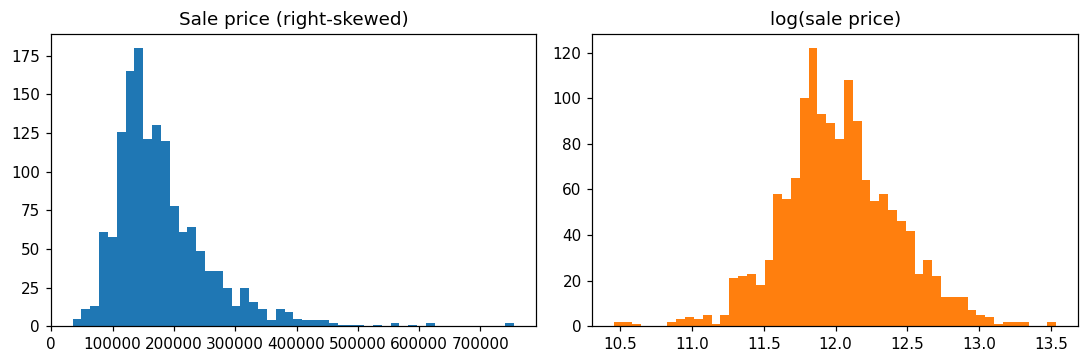

In [3]:
## ---- 1. Load, recode "none" values, check the target ---------------------------
NEED = ["train.csv", "test.csv", "sample_submission.csv"]
get_files(NEED)
train_raw = pd.read_csv(os.path.join(DATA_DIR, "train.csv")); test_raw = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
sample = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))
print("train:", train_raw.shape, " test:", test_raw.shape)
assert "SalePrice" in train_raw and len(test_raw) == len(sample)
FP = fingerprint(NEED)
out = (train_raw.GrLivArea > 4000) & (train_raw.SalePrice < 300000)
print(f"removed as partial sales (over 4,000 sq ft, under $300k): {int(out.sum())} rows, Ids {train_raw.loc[out, 'Id'].tolist()}")
train_df = train_raw.loc[~out].reset_index(drop=True)
y = np.log(train_df.SalePrice.values)
full = pd.concat([train_df.drop(columns="SalePrice"), test_raw], ignore_index=True)
n_tr = len(train_df)
miss_before = full.isna().sum(); miss_before = miss_before[miss_before > 0].sort_values(ascending=False)
NONE_CAT = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
            "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "MasVnrType"]
ZERO_NUM = ["GarageYrBlt", "GarageArea", "GarageCars", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath",
            "BsmtHalfBath", "MasVnrArea"]
for c in NONE_CAT: full[c] = full[c].fillna("None")
for c in ZERO_NUM: full[c] = full[c].fillna(0)
full["LotFrontage"] = full.groupby("Neighborhood").LotFrontage.transform(lambda s: s.fillna(s.median())).fillna(full.LotFrontage.median())
for c in full.columns:
    if full[c].isna().any():
        full[c] = full[c].fillna(full[c].median() if pd.api.types.is_numeric_dtype(full[c]) else full[c].mode()[0])
full["MSSubClass"] = full["MSSubClass"].astype(str)          # a dwelling-type code, not a quantity
print(f"columns with gaps before cleaning: {len(miss_before)}; after: {int(full.isna().any().sum())}")
print(miss_before.head(10).to_dict())
print(f"SalePrice skewness: raw {stats.skew(train_df.SalePrice):.2f}, log {stats.skew(y):.2f}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(train_df.SalePrice, bins=50); ax[0].set_title("Sale price (right-skewed)")
ax[1].hist(y, bins=50, color="C1"); ax[1].set_title("log(sale price)")
save_fig("A8_house_fig_target.png")
RESULTS["data"] = {"n_train_raw": len(train_raw), "n_removed": int(out.sum()), "n_train": n_tr, "n_test": len(test_raw), "sha256": FP,
                   "cols_with_gaps": int(len(miss_before)), "top_gaps": miss_before.head(8).to_dict(),
                   "skew_raw": float(stats.skew(train_df.SalePrice)), "skew_log": float(stats.skew(y))}

## Part 2. Features: dummies, ordinal scores, interactions, and polynomial terms
* **Ordinal scores:** quality and condition ratings (Po < Fa < TA < Gd < Ex) become 0 to 5 so their order is kept.
* **Combined measures:** total square footage (basement + first + second floor), total bathrooms, house age and years since remodel at sale, and total porch area.
* **Dichotomous variables:** every categorical column is one-hot encoded (0/1 dummies, one level dropped), for example `CentralAir_Y` and each neighbourhood.
* **Interactions:** quality × total square footage (a large house is worth more when it is also well built), house age × remodel age, and central air × living area.
* **Polynomial terms:** squares of overall quality, total square footage, and house age, so price can curve rather than rise in a straight line.
* **Transformation of skewed predictors:** log(1 + x) for numeric predictors with skewness above 0.75. Part 3 tests whether this helps.

In [4]:
## ---- 2. Features: ordinal scores, dummies, interactions, polynomials -----------
QMAP = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
for c in ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC", "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]:
    full[c + "_score"] = full[c].map(QMAP).fillna(0)
f = full
f["TotalSF"] = f.TotalBsmtSF + f["1stFlrSF"] + f["2ndFlrSF"]
f["TotalBath"] = f.FullBath + .5 * f.HalfBath + f.BsmtFullBath + .5 * f.BsmtHalfBath
f["HouseAge"] = (f.YrSold - f.YearBuilt).clip(lower=0); f["RemodAge"] = (f.YrSold - f.YearRemodAdd).clip(lower=0)
f["PorchSF"] = f.OpenPorchSF + f.EnclosedPorch + f["3SsnPorch"] + f.ScreenPorch + f.WoodDeckSF
f["CentralAir_Y"] = (f.CentralAir == "Y").astype(float)
f.drop(columns="CentralAir", inplace=True)                  # replaced by the 0/1 flag above
# interactions and polynomial terms (on standardized-scale-friendly units)
f["Qual_x_TotalSF"] = f.OverallQual * f.TotalSF / 1000
f["Age_x_RemodAge"] = f.HouseAge * f.RemodAge / 100
f["Air_x_GrLiv"] = f.CentralAir_Y * f.GrLivArea / 1000
f["OverallQual_sq"] = f.OverallQual ** 2; f["TotalSF_sq"] = (f.TotalSF / 1000) ** 2; f["HouseAge_sq"] = (f.HouseAge / 10) ** 2
ENGINEERED = ["Qual_x_TotalSF", "Age_x_RemodAge", "Air_x_GrLiv", "OverallQual_sq", "TotalSF_sq", "HouseAge_sq"]
cat_cols = [c for c in f.columns if not pd.api.types.is_numeric_dtype(f[c])]
num_cols = [c for c in f.columns if c not in cat_cols + ["Id"]]
skewed = [c for c in num_cols if c not in ENGINEERED and f[c].nunique() > 10 and abs(stats.skew(f[c])) > .75 and f[c].min() >= 0]
def design(log_skewed=True):
    g = f[num_cols].copy()
    if log_skewed:
        g[skewed] = np.log1p(g[skewed])
    d = pd.concat([g, pd.get_dummies(f[cat_cols], drop_first=True, dtype=float)], axis=1)
    d = d.loc[:, d.iloc[:n_tr].std() > 0]                      # drop columns constant in training
    return d.iloc[:n_tr].reset_index(drop=True), d.iloc[n_tr:].reset_index(drop=True)
X, X_test = design(True)
X_noskew, _ = design(False)
print(f"numeric predictors: {len(num_cols)} (log1p applied to {len(skewed)} skewed ones); categorical columns: {len(cat_cols)}")
print(f"design matrix: {X.shape[1]} columns ({sum(c in ENGINEERED for c in X.columns)} interaction/polynomial terms, "
      f"{X.shape[1] - len(num_cols)} dummies)")
RESULTS["features"] = {"n_numeric": len(num_cols), "n_skewed_logged": len(skewed), "skewed": skewed, "n_categorical": len(cat_cols),
                       "n_columns": int(X.shape[1]), "engineered": ENGINEERED}

numeric predictors: 57 (log1p applied to 20 skewed ones); categorical columns: 43
design matrix: 292 columns (6 interaction/polynomial terms, 235 dummies)


## Part 3. Transformations and subset selection
**Transformations.** One model (the lasso of Part 4, Model 1) is scored by 5-fold CV under three set-ups: raw price as the target; log price with raw predictors; and log price with log(1 + x) applied to skewed predictors. All three errors are measured on the log-price scale, so they are comparable.

**Subsets.** Two methods from ISLP Chapter 6 are used:
* **Forward stepwise selection:** starting from no predictors, add the one that most improves the fit, and pick the model size by BIC. It runs on 40 candidate predictors: the strongest numeric ones plus the engineered terms, since forward selection over all 250+ dummies would mostly select noise.
* **The lasso:** its penalty shrinks weak coefficients exactly to zero, so it selects a subset from all columns at once. The penalty is the largest within one standard error of the best CV error (the "one-SE rule"): a simpler model that the data cannot tell apart from the best one.

CV RMSE on log price by transformation: {'raw price target': 0.1353, 'log price, raw predictors': 0.1155, 'log price, log1p skewed predictors': 0.1154} (27 s)
forward stepwise: BIC picks 16 predictors; CV RMSE 0.1311; first ten added: ['Qual_x_TotalSF', 'Age_x_RemodAge', 'LotArea', 'GarageCond_score', 'TotalBath', 'FireplaceQu_score', 'HeatingQC_score', 'CentralAir_Y', 'TotalSF_sq', 'TotalSF']
lasso: alpha at min CV error 0.00335 keeps 92 columns; one-SE alpha 0.00767 keeps 59
one-SE rule: min CV MSE 0.01290, its SE across folds 0.00093, threshold 0.01383


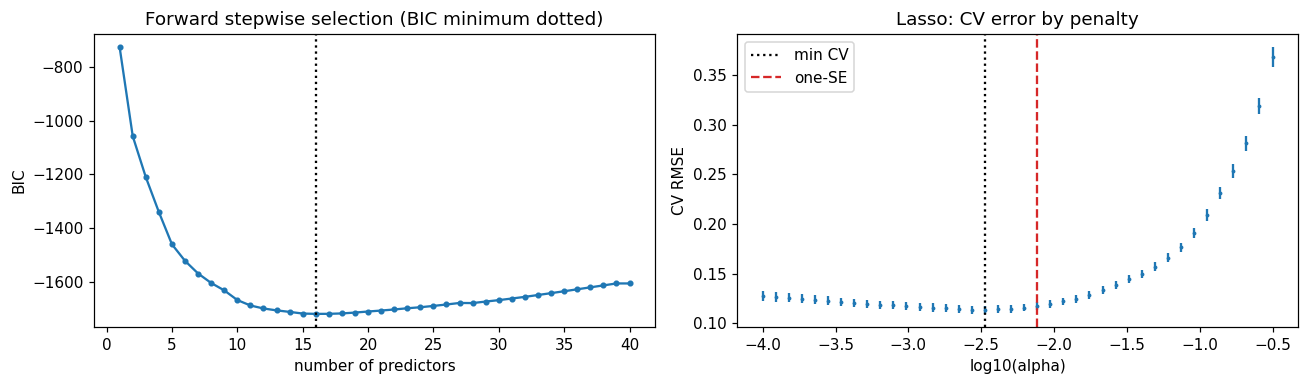

In [5]:
## ---- 3. Transformations and subset selection (forward stepwise, lasso one-SE) ---
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.linear_model import LassoCV, Lasso, LinearRegression, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
import statsmodels.api as sm
KF = KFold(5, shuffle=True, random_state=42)
rmse = lambda a, b: float(np.sqrt(np.mean((a - b) ** 2)))
ALPHAS = np.logspace(-4, -0.5, 40)
def lasso_cv_rmse(Xm, target, back=lambda p: p):
    grid = ALPHAS * np.std(target) / np.std(y)               # same relative penalty grid on either target scale
    p = cross_val_predict(make_pipeline(StandardScaler(), LassoCV(alphas=grid, cv=KF, max_iter=20000)), Xm, target, cv=KF)
    return rmse(y, back(p))
t0 = time.time()
trans = {"raw price target": lasso_cv_rmse(X, np.exp(y), back=lambda p: np.log(np.clip(p, 1e4, None))),
         "log price, raw predictors": lasso_cv_rmse(X_noskew, y),
         "log price, log1p skewed predictors": lasso_cv_rmse(X, y)}
print("CV RMSE on log price by transformation:", {k: round(v, 4) for k, v in trans.items()}, f"({time.time() - t0:.0f} s)")

# ---- forward stepwise selection by BIC on 40 candidates ----
num_rank = X[[c for c in num_cols if c in X]].corrwith(pd.Series(y)).abs().sort_values(ascending=False)
cands = list(dict.fromkeys([c for c in ENGINEERED if c in X] + list(num_rank.index)))[:40]
chosen, path = [], []
remaining = list(cands)
while remaining:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      # a candidate that is an exact sum of chosen ones adds nothing and is never picked
        best = min(remaining, key=lambda c: sm.OLS(y, sm.add_constant(X[chosen + [c]])).fit().ssr)
        chosen.append(best); remaining.remove(best)
        fit = sm.OLS(y, sm.add_constant(X[chosen])).fit()
    path.append({"k": len(chosen), "added": best, "bic": fit.bic, "adj_r2": fit.rsquared_adj})
path = pd.DataFrame(path); k_bic = int(path.loc[path.bic.idxmin(), "k"])
fwd_vars = chosen[:k_bic]
fwd_cv = rmse(y, cross_val_predict(LinearRegression(), X[fwd_vars], y, cv=KF))
print(f"forward stepwise: BIC picks {k_bic} predictors; CV RMSE {fwd_cv:.4f}; first ten added: {fwd_vars[:10]}")

# ---- lasso path with the one-SE rule ----
sc = StandardScaler().fit(X); Xs = sc.transform(X)
lcv = LassoCV(alphas=ALPHAS, cv=KF, max_iter=20000).fit(Xs, y)
mse_mean = lcv.mse_path_.mean(1); mse_se = lcv.mse_path_.std(1) / np.sqrt(KF.get_n_splits())
i_min = int(np.argmin(mse_mean)); thr = mse_mean[i_min] + mse_se[i_min]
alpha_1se = float(max(lcv.alphas_[mse_mean <= thr])); alpha_min = float(lcv.alpha_)
n_kept = {a: int((Lasso(alpha=a, max_iter=20000).fit(Xs, y).coef_ != 0).sum()) for a in (alpha_min, alpha_1se)}
print(f"lasso: alpha at min CV error {alpha_min:.5f} keeps {n_kept[alpha_min]} columns; one-SE alpha {alpha_1se:.5f} keeps {n_kept[alpha_1se]}")
print(f"one-SE rule: min CV MSE {mse_mean[i_min]:.5f}, its SE across folds {mse_se[i_min]:.5f}, threshold {thr:.5f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(path.k, path.bic, "o-", ms=3); ax[0].axvline(k_bic, ls=":", c="k"); ax[0].set_xlabel("number of predictors"); ax[0].set_ylabel("BIC")
ax[0].set_title("Forward stepwise selection (BIC minimum dotted)")
ax[1].errorbar(np.log10(lcv.alphas_), np.sqrt(mse_mean), yerr=mse_se / (2 * np.sqrt(mse_mean)), fmt=".", ms=3)
ax[1].axvline(np.log10(alpha_min), ls=":", c="k", label="min CV"); ax[1].axvline(np.log10(alpha_1se), ls="--", c="C3", label="one-SE")
ax[1].set_xlabel("log10(alpha)"); ax[1].set_ylabel("CV RMSE"); ax[1].legend(); ax[1].set_title("Lasso: CV error by penalty")
save_fig("A8_house_fig_selection.png")
RESULTS["transform"] = trans
RESULTS["subset"] = {"forward_k_bic": k_bic, "forward_vars": fwd_vars, "forward_cv": fwd_cv, "candidates": len(cands),
                     "lasso_alpha_min": alpha_min, "lasso_alpha_1se": alpha_1se, "lasso_kept_min": n_kept[alpha_min], "lasso_kept_1se": n_kept[alpha_1se],
                     "lasso_mse_min": float(mse_mean[i_min]), "lasso_mse_se": float(mse_se[i_min])}

## Part 4. The two Kaggle models
* **Model 1: lasso-selected linear regression.** All dummies, interactions, polynomial terms, and log-transformed skewed predictors enter, and the lasso at the one-SE penalty keeps a subset and shrinks it.
* **Model 2: principal components regression (PCR).** The same standardized columns are compressed into M principal components, and log price is regressed on them by least squares. M is chosen by CV as the smallest number within 1% of the best error. This is the dimension-reduction model.

Both are scored by 5-fold CV and then refit on all training rows for Kaggle. **Why 1%?** The cell prints the RMSE of each of the 5 folds at the chosen M and at the best M, with their standard deviation and standard error. If 1% of the best error is smaller than one standard error across folds, models inside the band cannot be told apart, and the smaller one is kept. The same fold numbers give a paired standard error for the lasso-versus-PCR gap.

Model 1 (lasso, one-SE): CV RMSE 0.1173
PCR CV RMSE by M: {5: 0.1468, 10: 0.1389, 20: 0.1357, 40: 0.1334, 60: 0.1299, 80: 0.1281, 100: 0.1264, 130: 0.1264, 160: 0.1237, 200: 0.1268, 240: 0.131, 280: 0.1431} -> M = 160 (94% of predictor variance)
Model 2 (PCR, M = 160): CV RMSE 0.1237
fold RMSE, PCR M = 160: [0.1304, 0.1224, 0.1226, 0.1331, 0.1088] (SD 0.0095, SE 0.0042)
the 1% band = 0.0012 on the log scale, vs one fold SE of 0.0042; best M = 160 (CV 0.1237)
fold RMSE, lasso: [0.1249, 0.1081, 0.128, 0.1197, 0.1039] (SD 0.0105)
PCR minus lasso, paired by fold: mean +0.0065, SE 0.0036; lasso better in 4 of 5 folds
(reference) ridge on all columns: CV RMSE 0.1199; forward-stepwise OLS: 0.1311
saved /content/drive/MyDrive/DDS8555/output/A8_house_model1_lasso.csv (1459, 2) median predicted price $157,199


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

saved /content/drive/MyDrive/DDS8555/output/A8_house_model2_pcr.csv (1459, 2) median predicted price $156,305


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

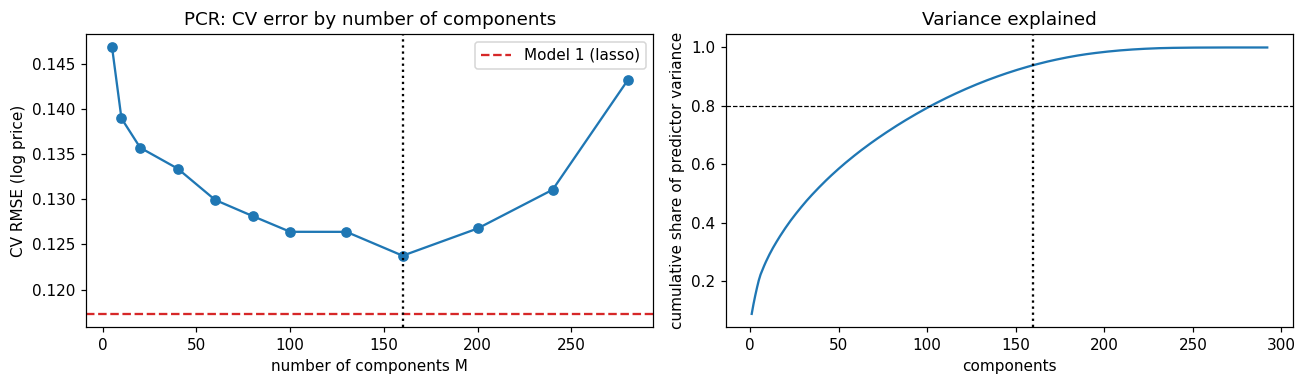

In [6]:
## ---- 4. Model 1 (lasso) and Model 2 (PCR); Kaggle files ------------------------
m1 = make_pipeline(StandardScaler(), Lasso(alpha=alpha_1se, max_iter=20000))
pred1 = cross_val_predict(m1, X, y, cv=KF)
cv1 = rmse(y, pred1)
M_GRID = [5, 10, 20, 40, 60, 80, 100, 130, 160, 200, 240, 280]
M_GRID = [m for m in M_GRID if m < X.shape[1]]
FOLDS = [te for _, te in KF.split(X)]
fold_rmse = lambda pred: np.array([rmse(y[te], pred[te]) for te in FOLDS])     # RMSE of each of the 5 CV folds
pcr_pred = {m: cross_val_predict(make_pipeline(StandardScaler(), PCA(n_components=m, svd_solver="full"), LinearRegression()), X, y, cv=KF) for m in M_GRID}
pcr_cv = {m: rmse(y, p) for m, p in pcr_pred.items()}
M_best = min(m for m, v in pcr_cv.items() if v <= min(pcr_cv.values()) * 1.01)
m2 = make_pipeline(StandardScaler(), PCA(n_components=M_best, svd_solver="full"), LinearRegression()); cv2 = pcr_cv[M_best]
evr = PCA(svd_solver="full").fit(StandardScaler().fit_transform(X)).explained_variance_ratio_.cumsum()
print(f"Model 1 (lasso, one-SE): CV RMSE {cv1:.4f}")
print("PCR CV RMSE by M:", {k: round(v, 4) for k, v in pcr_cv.items()}, f"-> M = {M_best} ({evr[M_best - 1]:.0%} of predictor variance)")
print(f"Model 2 (PCR, M = {M_best}): CV RMSE {cv2:.4f}")
M_min = min(pcr_cv, key=pcr_cv.get)
f_lasso, f_pcr, f_pmin = fold_rmse(pred1), fold_rmse(pcr_pred[M_best]), fold_rmse(pcr_pred[M_min])
sd_pcr = float(f_pcr.std(ddof=1)); se_pcr = sd_pcr / np.sqrt(len(FOLDS))
band = .01 * pcr_cv[M_min]
d_lp = f_pcr - f_lasso; se_lp = float(d_lp.std(ddof=1) / np.sqrt(len(FOLDS)))
print(f"fold RMSE, PCR M = {M_best}: {np.round(f_pcr, 4).tolist()} (SD {sd_pcr:.4f}, SE {se_pcr:.4f})")
print(f"the 1% band = {band:.4f} on the log scale, vs one fold SE of {se_pcr:.4f}; best M = {M_min} (CV {pcr_cv[M_min]:.4f})")
print(f"fold RMSE, lasso: {np.round(f_lasso, 4).tolist()} (SD {f_lasso.std(ddof=1):.4f})")
print(f"PCR minus lasso, paired by fold: mean {d_lp.mean():+.4f}, SE {se_lp:.4f}; lasso better in {int((d_lp > 0).sum())} of {len(FOLDS)} folds")
ridge_cv = rmse(y, cross_val_predict(make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 3, 30))), X, y, cv=KF))
print(f"(reference) ridge on all columns: CV RMSE {ridge_cv:.4f}; forward-stepwise OLS: {fwd_cv:.4f}")
m1.fit(X, y); m2.fit(X, y)
for name, m in (("A8_house_model1_lasso.csv", m1), ("A8_house_model2_pcr.csv", m2)):
    pred = np.exp(m.predict(X_test))
    sub = pd.DataFrame({"Id": test_raw.Id.values, "SalePrice": pred}); path_ = os.path.join(OUT_DIR, name)
    sub.to_csv(path_, index=False); print("saved", path_, sub.shape, f"median predicted price ${np.median(pred):,.0f}"); download(path_)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(list(pcr_cv), list(pcr_cv.values()), "o-"); ax[0].axhline(cv1, ls="--", c="C3", label="Model 1 (lasso)"); ax[0].axvline(M_best, ls=":", c="k")
ax[0].set_xlabel("number of components M"); ax[0].set_ylabel("CV RMSE (log price)"); ax[0].legend(); ax[0].set_title("PCR: CV error by number of components")
ax[1].plot(range(1, len(evr) + 1), evr); ax[1].axhline(.8, ls="--", c="k", lw=.8); ax[1].axvline(M_best, ls=":", c="k")
ax[1].set_xlabel("components"); ax[1].set_ylabel("cumulative share of predictor variance"); ax[1].set_title("Variance explained")
save_fig("A8_house_fig_pcr.png")
RESULTS["models"] = {"lasso": {"cv_rmse": cv1, "alpha": alpha_1se, "kept": int((m1[-1].coef_ != 0).sum())},
                     "pcr": {"cv_rmse": cv2, "M": M_best, "var_share": float(evr[M_best - 1]), "grid": pcr_cv,
                             "M_min": int(M_min), "band_1pct": float(band), "fold_rmse": f_pcr, "fold_sd": sd_pcr, "fold_se": float(se_pcr)},
                     "lasso_fold_rmse": f_lasso, "lasso_fold_sd": float(f_lasso.std(ddof=1)),
                     "pcr_minus_lasso": {"mean": float(d_lp.mean()), "se": se_lp, "lasso_better_folds": int((d_lp > 0).sum())},
                     "ridge_ref": ridge_cv, "forward_ref": fwd_cv}

## Part 5. Interpreting Model 1
With log price as the target, a coefficient b means that a one-unit increase in that predictor multiplies price by e^b, or roughly 100·b percent for small b. The lasso works on standardized columns, and several predictors are on a log scale, so its effects are shown per one-standard-deviation increase, which puts all predictors on the same footing. To get readable, unshrunk effects with standard errors, an ordinary least squares refit on the forward-stepwise subset is also shown, with both the usual standard errors and HC3 heteroscedasticity-robust ones (Part 6 shows the error variance is not constant, which makes the usual standard errors and p-values unreliable; robust ones correct for that). That refit is also the model used for the residual assumption checks in Part 6.

In [7]:
## ---- 5. Interpreting Model 1 ---------------------------------------------------
coef = pd.Series(m1[-1].coef_, index=X.columns)              # per one standard deviation of each column
kept = coef[coef != 0]
top = kept.abs().sort_values(ascending=False).head(15).index
print("Largest lasso effects (% change in price for a one-standard-deviation increase):")
print((100 * (np.exp(kept[top]) - 1)).round(2).to_string())
ols = sm.OLS(y, sm.add_constant(X[fwd_vars])).fit()
show = [v for v in ["OverallQual", "TotalSF", "Qual_x_TotalSF", "OverallQual_sq", "HouseAge", "HouseAge_sq", "CentralAir_Y", "Air_x_GrLiv",
                    "GarageCars", "TotalBath", "KitchenQual_score"] if v in fwd_vars]
tab = pd.DataFrame({"coef": ols.params[show], "pct_per_unit": 100 * (np.exp(ols.params[show]) - 1), "p": ols.pvalues[show]})
ols_hc3 = sm.OLS(y, sm.add_constant(X[fwd_vars])).fit(cov_type="HC3")      # heteroscedasticity-robust standard errors
tab["se_classic"] = ols.bse[show]; tab["se_hc3"] = ols_hc3.bse[show]; tab["p_hc3"] = ols_hc3.pvalues[show]
print("\nOLS refit on the forward-stepwise subset (selected terms; classic and HC3 robust standard errors):"); print(tab.round(4))
se_ratio = (ols_hc3.bse / ols.bse).drop("const")
sig_c, sig_r = int((ols.pvalues.drop("const") < .05).sum()), int((ols_hc3.pvalues.drop("const") < .05).sum())
print(f"HC3 / classic SE ratio across all {len(fwd_vars)} predictors: median {se_ratio.median():.2f}, max {se_ratio.max():.2f} ({se_ratio.idxmax()}); "
      f"significant at .05: {sig_c} with classic SEs, {sig_r} with HC3")
print(f"OLS refit: R2 = {ols.rsquared:.3f}, adj. R2 = {ols.rsquared_adj:.3f}, {len(fwd_vars)} predictors")
RESULTS["interpret"] = {"lasso_top_pct": (100 * (np.exp(kept[top]) - 1)).round(3).to_dict(), "ols_r2": ols.rsquared, "ols_adj_r2": ols.rsquared_adj,
                        "ols_terms": tab.round(5).to_dict(), "engineered_kept": [e for e in ENGINEERED if e in kept.index],
                        "hc3": {"se_ratio_median": float(se_ratio.median()), "se_ratio_max": float(se_ratio.max()), "se_ratio_max_term": se_ratio.idxmax(),
                                "sig_classic": sig_c, "sig_hc3": sig_r, "n_terms": len(fwd_vars)},
                        "engineered_in_forward": [e for e in ENGINEERED if e in fwd_vars]}

Largest lasso effects (% change in price for a one-standard-deviation increase):
Qual_x_TotalSF          11.42
GrLivArea                4.69
LotArea                  4.08
HouseAge                -3.62
OverallCond              3.72
TotalSF                  3.62
OverallQual              3.15
TotalBath                2.47
GarageCars               2.02
Age_x_RemodAge          -1.97
BsmtFinSF1               1.93
SaleType_New             1.92
Neighborhood_Crawfor     1.51
KitchenQual_score        1.45
GarageArea               1.32

OLS refit on the forward-stepwise subset (selected terms; classic and HC3 robust standard errors):
                     coef  pct_per_unit       p  se_classic  se_hc3   p_hc3
TotalSF            0.3271       38.6881  0.0000      0.0352  0.0471  0.0000
Qual_x_TotalSF     0.0304        3.0895  0.0000      0.0015  0.0015  0.0000
HouseAge_sq       -0.0007       -0.0729  0.0000      0.0002  0.0002  0.0002
CentralAir_Y       0.1803       19.7565  0.0000      0.0355  0.05

## Part 6. Assumption checks (OLS refit on the forward-stepwise subset)
Linear regression inference assumes linearity, independent errors, constant error variance, and roughly normal errors, with no extreme multicollinearity or highly influential points. The checks are: residuals versus fitted values, a normal Q-Q plot, Breusch-Pagan (constant variance), Durbin-Watson (independence, in Id order), Jarque-Bera (normality), variance inflation factors (VIF), and Cook's distance. The interaction and squared terms are correlated with their parent variables by construction, so their VIFs are high by design. That makes single coefficients less stable but does not affect predictions.

Breusch-Pagan: stat 79.1, p = 2.39e-10;  Durbin-Watson 2.046;  Jarque-Bera 1868.9, p = 0.00e+00, skew -1.09, kurtosis 8.10
Largest VIFs: {'TotalSF_sq': 19.7, 'Air_x_GrLiv': 18.3, 'Qual_x_TotalSF': 13.2, 'TotalBsmtSF': 10.6, 'TotalSF': 10.3, 'CentralAir_Y': 6.7}
Largest VIFs excluding interaction/polynomial terms: {'TotalBsmtSF': 10.6, 'TotalSF': 10.3, 'CentralAir_Y': 6.7, 'GarageCars': 2.6}
Cook's distance above 4/n: 101 homes (6.9%); max 0.085


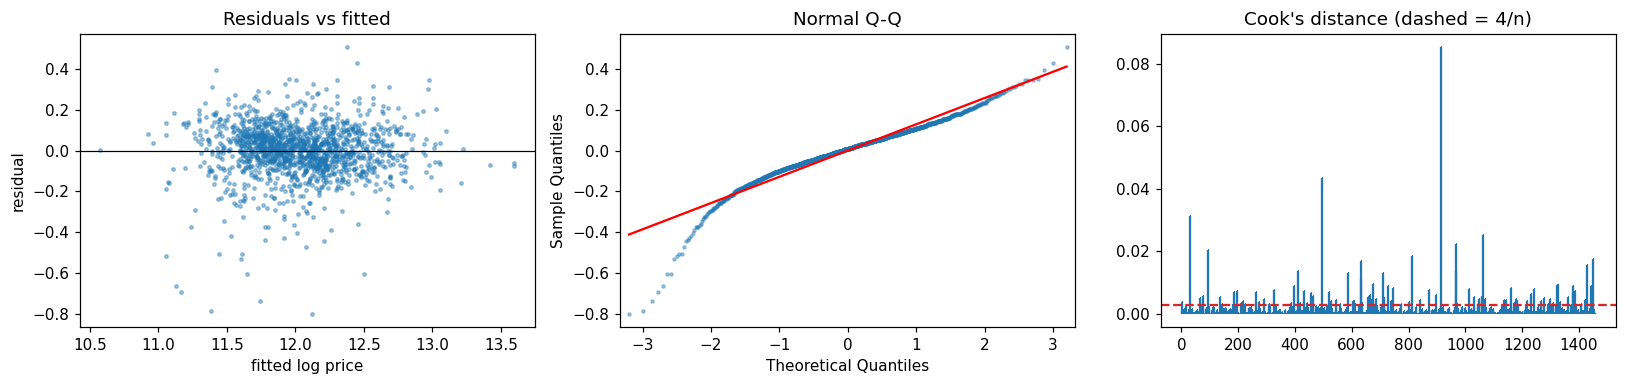

In [8]:
## ---- 6. Assumption checks ------------------------------------------------------
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
r = ols.resid; fv = ols.fittedvalues
bp = het_breuschpagan(r, ols.model.exog); jb = jarque_bera(r); dw = durbin_watson(r)
Xv = sm.add_constant(X[fwd_vars]).values
vif = pd.Series([variance_inflation_factor(Xv, i + 1) for i in range(len(fwd_vars))], index=fwd_vars).sort_values(ascending=False)
cook = OLSInfluence(ols).cooks_distance[0]; n_cook = int((cook > 4 / len(y)).sum())
print(f"Breusch-Pagan: stat {bp[0]:.1f}, p = {bp[1]:.2e};  Durbin-Watson {dw:.3f};  Jarque-Bera {jb[0]:.1f}, p = {jb[1]:.2e}, skew {jb[2]:.2f}, kurtosis {jb[3]:.2f}")
print("Largest VIFs:", vif.head(6).round(1).to_dict())
vif_core = vif[[v for v in vif.index if v not in ENGINEERED]]
print("Largest VIFs excluding interaction/polynomial terms:", vif_core.head(4).round(1).to_dict())
print(f"Cook's distance above 4/n: {n_cook} homes ({n_cook / len(y):.1%}); max {cook.max():.3f}")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].scatter(fv, r, s=5, alpha=.4); ax[0].axhline(0, c="k", lw=.8); ax[0].set_xlabel("fitted log price"); ax[0].set_ylabel("residual"); ax[0].set_title("Residuals vs fitted")
sm.qqplot(r, line="s", ax=ax[1], markersize=2, alpha=.4); ax[1].set_title("Normal Q-Q")
ax[2].stem(cook, markerfmt=",", basefmt=" "); ax[2].axhline(4 / len(y), ls="--", c="C3"); ax[2].set_title("Cook's distance (dashed = 4/n)")
save_fig("A8_house_fig_resid.png")
RESULTS["checks"] = {"bp_stat": bp[0], "bp_p": bp[1], "dw": dw, "jb_stat": jb[0], "jb_p": jb[1], "skew": jb[2], "kurtosis": jb[3],
                     "vif_top": vif.head(6).round(2).to_dict(), "vif_core_top": vif_core.head(4).round(2).to_dict(), "n_cook": n_cook, "cook_max": float(cook.max())}

In [9]:
## ---- 7. Plain-language reading -------------------------------------------------
# ---- Plain-language reading (generated from the numbers above) ----
T_ = RESULTS["transform"]; Mo = RESULTS["models"]; Ck = RESULTS["checks"]; Su = RESULTS["subset"]
print("* Transformations (CV RMSE, log price): " + "; ".join(f"{k} {v:.4f}" for k, v in T_.items()) + ".")
print(f"* Subsets: forward stepwise keeps {Su['forward_k_bic']} of {Su['candidates']} candidates (CV {Su['forward_cv']:.4f}); "
      f"the one-SE lasso keeps {Su['lasso_kept_1se']} of {RESULTS['features']['n_columns']} columns.")
gap = Mo['pcr']['cv_rmse'] - Mo['lasso']['cv_rmse']
print(f"* Model 1 (lasso) CV RMSE {Mo['lasso']['cv_rmse']:.4f}; Model 2 (PCR, M = {Mo['pcr']['M']}) {Mo['pcr']['cv_rmse']:.4f}. "
      f"An RMSE of {Mo['lasso']['cv_rmse']:.3f} on the log scale is a typical error of about {(np.exp(Mo['lasso']['cv_rmse']) - 1) * 100:.0f}% of price; "
      f"the gap between the models, {gap:+.4f}, is about {abs(gap) * 100:.1f} percentage points.")
print(f"* Engineered terms the lasso keeps: {RESULTS['interpret']['engineered_kept']}.")
_p = Mo["pcr"]; _g = Mo["pcr_minus_lasso"]
_tied = _p['band_1pct'] < _p['fold_se']
print(f"* PCR's 1% band ({_p['band_1pct']:.4f}) is {'smaller' if _tied else 'larger'} than one fold standard error ({_p['fold_se']:.4f}), "
      + (f"so any M inside the band is a statistical tie with the best; here the chosen M = {_p['M']} is itself the lowest-error M on the grid. "
         if _p['M'] == _p['M_min'] else
         f"so M = {_p['M']} is {'statistically tied with' if _tied else 'distinguishable from'} the best M = {_p['M_min']}. ")
      + f"PCR minus lasso, paired by fold: {_g['mean']:+.4f} (SE {_g['se']:.4f}); the lasso is better in {_g['lasso_better_folds']} of 5 folds.")
_h = RESULTS["interpret"]["hc3"]
print(f"* Robust (HC3) standard errors are a median {_h['se_ratio_median']:.2f} times the usual ones (up to {_h['se_ratio_max']:.2f}); "
      f"{_h['sig_hc3']} of {_h['n_terms']} predictors stay significant at .05 (vs {_h['sig_classic']} with the usual SEs).")
print(f"* Assumptions: Breusch-Pagan p = {Ck['bp_p']:.1e} (variance not constant), Jarque-Bera p = {Ck['jb_p']:.1e} with kurtosis {Ck['kurtosis']:.1f} "
      f"(heavy tails), Durbin-Watson {Ck['dw']:.2f} (no serial correlation). {Ck['n_cook']} homes exceed the 4/n Cook's distance guide.")

* Transformations (CV RMSE, log price): raw price target 0.1353; log price, raw predictors 0.1155; log price, log1p skewed predictors 0.1154.
* Subsets: forward stepwise keeps 16 of 40 candidates (CV 0.1311); the one-SE lasso keeps 59 of 292 columns.
* Model 1 (lasso) CV RMSE 0.1173; Model 2 (PCR, M = 160) 0.1237. An RMSE of 0.117 on the log scale is a typical error of about 12% of price; the gap between the models, +0.0064, is about 0.6 percentage points.
* Engineered terms the lasso keeps: ['Qual_x_TotalSF', 'Age_x_RemodAge', 'Air_x_GrLiv', 'OverallQual_sq'].
* PCR's 1% band (0.0012) is smaller than one fold standard error (0.0042), so any M inside the band is a statistical tie with the best; here the chosen M = 160 is itself the lowest-error M on the grid. PCR minus lasso, paired by fold: +0.0065 (SE 0.0036); the lasso is better in 4 of 5 folds.
* Robust (HC3) standard errors are a median 1.10 times the usual ones (up to 1.58); 16 of 16 predictors stay significant at .05 (vs 16 with

In [10]:
## ---- 8. Environment report and results JSON ------------------------------------
RESULTS_FILE = "A8_house_results.json"
# ---- Environment report (the Python equivalent of R's sessionInfo()) ----
import importlib, platform
VERSIONS = {"python": platform.python_version()}
for pkg in ("numpy", "pandas", "sklearn", "statsmodels", "scipy", "matplotlib", "ISLP"):
    try:
        VERSIONS[pkg] = importlib.import_module(pkg).__version__
    except Exception:
        VERSIONS[pkg] = "not installed"
print("Environment:", VERSIONS)
print(f"Total run time: {(time.time() - T0) / 60:.1f} min")
RESULTS["environment"] = VERSIONS

# ---- Results used in the paper (printed so they are saved in the notebook) ----
def _clean(o):
    if isinstance(o, dict):
        return {str(k): _clean(v) for k, v in o.items() if not str(k).startswith("_")}
    if isinstance(o, (list, tuple)):
        return [_clean(v) for v in o]
    if isinstance(o, np.ndarray):
        return _clean(o.tolist())
    if isinstance(o, (np.floating, np.integer, np.bool_)):
        return o.item()
    if isinstance(o, float) and o != o:
        return None
    return o
RESULTS = _clean(RESULTS)
with open(os.path.join(OUT_DIR, RESULTS_FILE), "w") as f:
    json.dump(RESULTS, f, indent=1)
print("RESULTS_JSON_START")
print(json.dumps(RESULTS))
print("RESULTS_JSON_END")

Environment: {'python': '3.13.18', 'numpy': '2.4.6', 'pandas': '2.2.3', 'sklearn': '1.6.1', 'statsmodels': '0.15.0', 'scipy': '1.16.3', 'matplotlib': '3.10.0', 'ISLP': '0.6.0'}
Total run time: 4.6 min
RESULTS_JSON_START
{"data": {"n_train_raw": 1460, "n_removed": 2, "n_train": 1458, "n_test": 1459, "sha256": {"train.csv": "1e18addf81e5e4d347cc17ee6075bbe4a42b7fa26b9e5b063e8f692a5f929d41", "test.csv": "8fdd3d829d4d986b58f845c9553b225e67dd8383624d90fb6ca1d4bed5798c1e", "sample_submission.csv": "f19e99699b925aa3085c8d2ae43c62f15fbcd35e4a953b98025f8392c3ffa807"}, "cols_with_gaps": 34, "top_gaps": {"PoolQC": 2908, "MiscFeature": 2812, "Alley": 2719, "Fence": 2346, "MasVnrType": 1766, "FireplaceQu": 1420, "LotFrontage": 486, "GarageQual": 159}, "skew_raw": 1.8793604459195012, "skew_log": 0.1214431084960451}, "features": {"n_numeric": 57, "n_skewed_logged": 20, "skewed": ["LotFrontage", "LotArea", "MasVnrArea", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "1stFlrSF", "2ndFlrSF", "LowQualFinSF", "